In [40]:
import numpy as np
import matplotlib.pyplot as plt

In [41]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def log_loss(w, X, y):
    m = len(y)
    z = np.dot(X, w)
    A = sigmoid(z)

    eps = 1e-15
    A = np.clip(A, eps, 1 - eps)

    loss = -np.mean(y * np.log(A) + (1 - y) * np.log(1 - A))
    grad = (1 / m) * np.dot(X.T, (A - y))

    return loss, grad

def optimize(w, X, y, n_iterations, eta):
    losses = []

    for _ in range(n_iterations):
        loss, grad = log_loss(w, X, y)
        w -= eta * grad
        losses.append(loss)

    return w, losses

def predict(w, X, b=0.5):
    A = sigmoid(np.dot(X, w))
    return (A >= b).astype(int)

In [42]:
np.random.seed(42)
m = 200
X = np.random.randn(m, 2)
true_w = np.array([2.0, -3.0])

probs = sigmoid(X @ true_w)
y = (probs > 0.5).astype(int)

# Свободный коэффициент
w = np.zeros(X.shape[1])

w_opt, loss_history = optimize(w, X, y, n_iterations=1000, eta=0.1)
print("Оптимальные веса:", w_opt)


Оптимальные веса: [ 2.99634557 -4.50676077]


Accuracy: 1.0


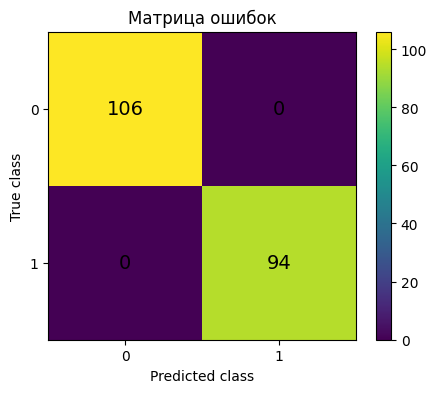

In [ ]:
# Оценка качества предсказаний
def plot_confusion_matrix(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1))
    tn = np.sum((y_pred == 0) & (y_true == 0))
    fp = np.sum((y_pred == 1) & (y_true == 0))
    fn = np.sum((y_pred == 0) & (y_true == 1))

    cm = np.array([[tn, fp],
                   [fn, tp]])

    plt.figure(figsize=(5, 4))
    plt.imshow(cm, interpolation='nearest')
    plt.title("Матрица ошибок")
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.xticks([0, 1], ["0", "1"])
    plt.yticks([0, 1], ["0", "1"])

    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i, j],
                     ha="center", va="center", fontsize=14)
    plt.colorbar()
    plt.show()

y_pred = predict(w_opt, X)
accuracy = np.mean(y_pred == y)
print("Accuracy:", accuracy)
plot_confusion_matrix(y, y_pred)


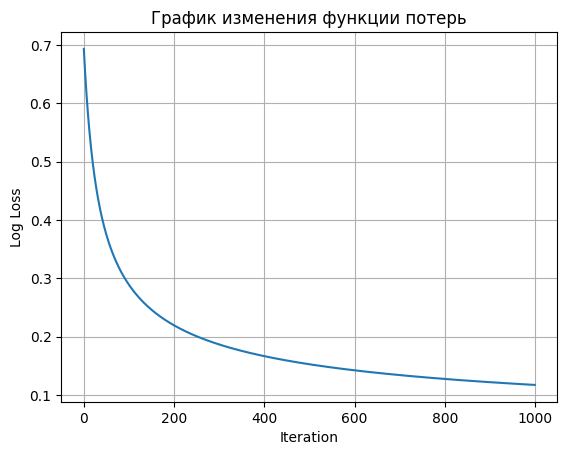

In [44]:
# График изменения функции потерь
plt.plot(loss_history)
plt.xlabel("Iteration")
plt.ylabel("Log Loss")
plt.title("График изменения функции потерь")
plt.grid()
plt.show()

### 1. Влияние шага обучения $\eta$

Шаг обучения определяет скорость сходимости градиентного спуска.
При слишком малом $\eta$ сходимость существенно замедляется, тогда как чрезмерно большое значение может привести к расходимости алгоритма или колебаниям около минимума функции потерь.

### 2. Влияние количества итераций n_iterations

При слишком малом числе итераций модель не успевает уменьшить функцию потерь и остаётся недообученной.
Слишком большое число итераций почти не улучшает качество и лишь увеличивает время обучения.

### 3. Почему логистическая регрессия — только для бинарной классификации

Логистическая регрессия использует сигмоиду, которая выдаёт вероятность только одного класса (от 0 до 1), а второй определяется как её дополнение.
Поэтому модель естественным образом работает именно с двумя классами.
